# ECG Anomaly Detection with Autoencoders (Version 2)
**Goal:** learn what a **normal heartbeat** looks like, then flag beats that look **unusual** 🚨

**Part A: Version 1 (baseline)**
1. Download MIT-BIH
2. Clean the signal + cut single beats
3. Cut beats from all patients (+ RR timing)
4. Labels + split by patient
5. Prepare the data (train = normal beats only)
6. Linear autoencoder
7. Train
8. Rebuild errors
9. Threshold + scores
10. Which beat types are caught

**Part B: Improvements**

11. Latent space: UMAP plot + K-Means (*MNIST_UMAP_vs_PCA*, *Clustering_on_CNN_Features*)
12. Conv1d denoising autoencoder (*Break It Then Fix It*)
13. KNN distance in latent space (*KNN / Qdrant vector search*)
14. RR timing score (*Feature engineering*)
15. Ensemble: combine the scores (*Ensembling*)
16. Final comparison + PR curves (*Classification threshold*)
17. K-Fold by patient: mean ± std (*K-Fold*)

# PART A: Version 1 (baseline)

## Step 1: Download the data + look at one patient

In [1]:
# download MIT-BIH as one ZIP (more reliable than wfdb.dl_database)
!wget -c -q --show-progress https://physionet.org/static/published-projects/mitdb/mit-bih-arrhythmia-database-1.0.0.zip
!unzip -q -o mit-bih-arrhythmia-database-1.0.0.zip
!rm -rf mitdb
!mv mit-bih-arrhythmia-database-1.0.0 mitdb
!pip install wfdb umap-learn -q
import wfdb
print("✅ downloaded")

mit-bih-arrhythmia- 100%[===================>]  73.46M  78.9MB/s    in 0.9s    
✅ downloaded


record is a patient folder. Inside are many cards, each with different info:
p_signal = one card that holds a table with the actual ECG
And sig_name is just the card that tells you the names of those 2 columns
There are 2 leads II, V5 and each number = the voltage (mV) the lead measured at that moment.

In [13]:
DATA = "mitdb"
record = wfdb.rdrecord(f"{DATA}/100")       # the signal (.dat + .hea)
pd.DataFrame(record.p_signal, columns=record.sig_name)


,MLII,V5
0,-0.145,-0.065
1,-0.145,-0.065
2,-0.145,-0.065
3,-0.145,-0.065
4,-0.145,-0.065
...,...,...
649995,-0.075,-0.480
649996,-0.445,-0.410
649997,-0.675,-0.365
649998,-0.765,-0.335


In [19]:
DATA = "mitdb"

# open patient 100
record = wfdb.rdrecord(f"{DATA}/100")       # the signal (.dat + .hea)
ann    = wfdb.rdann(f"{DATA}/100", "atr")   # the cardiologist labels (.atr)

print("signal shape:", record.p_signal.shape)   # (samples, leads)
print("sampling rate:", record.fs, "Hz")
print("leads:", record.sig_name)
print("number of beats:", len(ann.sample))

df_ann = pd.DataFrame({"sample": ann.sample, "symbol": ann.symbol})
print(list(vars(ann).keys()))

signal shape: (650000, 2)
sampling rate: 360 Hz
leads: ['MLII', 'V5']
number of beats: 2274
['record_name', 'extension', 'sample', 'symbol', 'subtype', 'chan', 'num', 'aux_note', 'fs', 'label_store', 'description', 'custom_labels', 'contained_labels', 'ann_len']


N= normal beat, sinus
A= Atrial premature beat
V= Ventricular premature beat
+= NOT a beat: a rhythm marker

ONLY OF PATIENT 100

In [16]:
# count the beat types of patient 100
import pandas as pd
pd.set_option("display.width", 200)          # show wide tables fully
pd.set_option("display.max_columns", 20)
print(pd.Series(ann.symbol).value_counts()) #counts how many times each label appears

N    2239
A      33
+       1
V       1
Name: count, dtype: int64


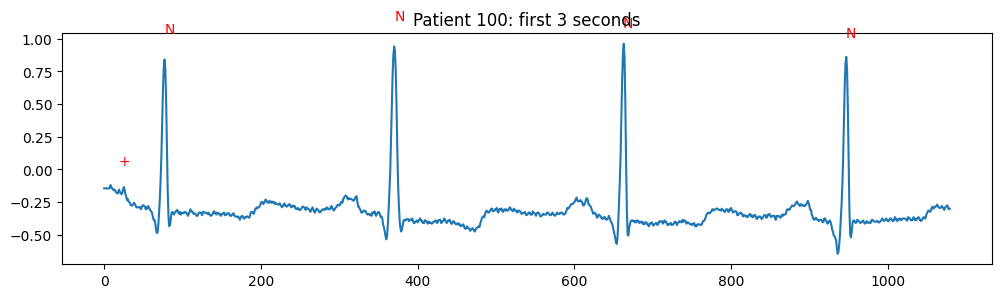

In [17]:
# plot 3 seconds with the beat labels
import matplotlib.pyplot as plt

fs = record.fs
signal = record.p_signal[:, 0]          # lead MLII
end = 3 * fs                            # 3 seconds

plt.figure(figsize=(12, 3))
plt.plot(signal[:end])
for s, sym in zip(ann.sample, ann.symbol):
    if s < end:
        plt.text(s, signal[s] + 0.2, sym, color="red")
plt.title("Patient 100: first 3 seconds")
plt.show()

## Step 2: Clean the signal + cut single beats (patient 100)

In [20]:
# bandpass filter 0.5–40 Hz: removes baseline wander + high-frequency noise
import numpy as np
from scipy.signal import butter, filtfilt

def bandpass(sig, fs=360, low=0.5, high=40):
    b, a = butter(3, [low / (fs / 2), high / (fs / 2)], btype="band")
    return filtfilt(b, a, sig)

clean = bandpass(signal)
print("before:", signal[:5].round(2))
print("after: ", clean[:5].round(2))

before: [-0.14 -0.14 -0.14 -0.14 -0.14]
after:  [0.04 0.04 0.04 0.04 0.04]


In [21]:
# cut the beats: 90 points before the R peak + 160 after = 250 points (P + QRS + T)
BEFORE = 90 #90 ÷ 360  = 0.25 s  → enough to include the P wave
AFTER = 160 #160 ÷ 360 = 0.44 s  → enough to include the T wave
BEAT_TYPES = ["N", "L", "R", "e", "j", "A", "a", "J", "S", "V", "E", "F", "/", "f", "Q"]

beats = []
labels = []

for s, sym in zip(ann.sample, ann.symbol):
    if sym not in BEAT_TYPES:          # skip markers like "+"
        continue
    if s - BEFORE < 0 or s + AFTER > len(clean):   # too close to the edge
        continue
    beats.append(clean[s - BEFORE : s + AFTER])
    labels.append(sym)

beats = np.array(beats)
labels = np.array(labels)
print("beats shape:", beats.shape)
print("labels:", np.unique(labels, return_counts=True))

beats shape: (2271, 250)
labels: (array(['A', 'N', 'V'], dtype='<U1'), array([  33, 2237,    1]))


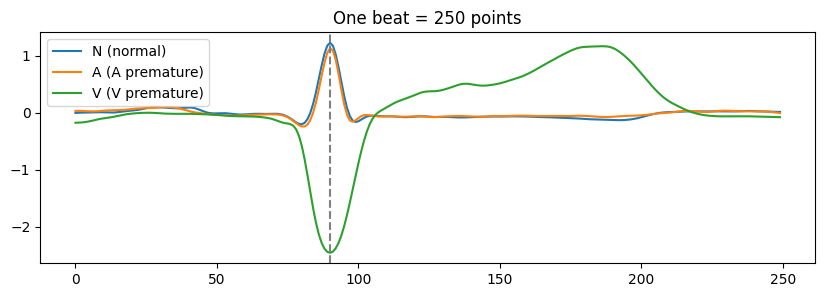

In [24]:
# a normal beat vs a PAC
normal_beat = beats[labels == "N"][0]
weird_beat  = beats[labels == "A"][0]
weird_beat_2  = beats[labels == "V"][0]

plt.figure(figsize=(10, 3))
plt.plot(normal_beat, label="N (normal)")
plt.plot(weird_beat, label="A (A premature)")
plt.plot(weird_beat_2, label="V (V premature)")
plt.axvline(BEFORE, color="gray", linestyle="--")   # R peak position
plt.legend()
plt.title("One beat = 250 points")
plt.show()

Shape can't tell N from A, timing can, the time between beats (the RR interval)

## Step 3: Cut beats from ALL recordings (+ RR timing)
 for every beat we also save its **timing**:
- `rr_prev` = seconds since the previous beat
- `rr_next` = seconds until the next beat
- `rr_mean` = this patient's average RR (to compare against)

A PAC comes **early** → `rr_prev` is short compared to `rr_mean`.

In [27]:
# list all the recordings (48 recordings = 47 patients; 201 + 202 are the same person)
import os # glob finds files by a name pattern
from glob import glob
files = sorted(glob(f"{DATA}/*.hea"))
records = []
for f in files:
    name = os.path.basename(f)       # "mitdb/100.hea" → "100.hea"
    name = name.replace(".hea", "")  # "100.hea" → "100"
    records.append(name)
print("number of recordings:", len(records))
print(records)

number of recordings: 48
['100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '111', '112', '113', '114', '115', '116', '117', '118', '119', '121', '122', '123', '124', '200', '201', '202', '203', '205', '207', '208', '209', '210', '212', '213', '214', '215', '217', '219', '220', '221', '222', '223', '228', '230', '231', '232', '233', '234']


In [37]:
# ---- find the patients with a pacemaker ("/" beats) -> skip them ----
PACED = []
for r in records:
    ann = wfdb.rdann(f"{DATA}/{r}", "atr")
    n_paced = ann.symbol.count("/")
    if n_paced > 0:
        print(r, "→", n_paced, "paced beats")
        PACED.append(r)
print("PACED:", PACED)

all_beats, all_labels, all_records = [], [], []
all_rr_prev, all_rr_next, all_rr_mean = [], [], []

for r in records:
    if r in PACED:
        continue
    rec = wfdb.rdrecord(f"{DATA}/{r}")            # read the signal
    ann = wfdb.rdann(f"{DATA}/{r}", "atr")        # read the labels
    clean = bandpass(rec.p_signal[:, 0])          # lead MLII, filtered

    beat_pos = np.array([s for s, sym in zip(ann.sample, ann.symbol) if sym in BEAT_TYPES])
    beat_sym = [sym for sym in ann.symbol if sym in BEAT_TYPES]

    rr = np.diff(beat_pos) / rec.fs               # time between beats (seconds)
    rr_mean = np.median(rr)                       # this patient's typical RR

    for i, (s, sym) in enumerate(zip(beat_pos, beat_sym)):
        if i == 0 or i == len(beat_pos) - 1:      # need a previous AND a next beat
            continue
        if s - BEFORE < 0 or s + AFTER > len(clean):
            continue
        all_beats.append(clean[s - BEFORE : s + AFTER])
        all_labels.append(sym)
        all_records.append(r)
        all_rr_prev.append(rr[i - 1])             # gap BEFORE this beat
        all_rr_next.append(rr[i])                 # gap AFTER this beat
        all_rr_mean.append(rr_mean)

all_beats   = np.array(all_beats)
all_labels  = np.array(all_labels)
all_records = np.array(all_records)
all_rr_prev = np.array(all_rr_prev)
all_rr_next = np.array(all_rr_next)
all_rr_mean = np.array(all_rr_mean)

print("beats:", all_beats.shape)
print("patients used:", len(np.unique(all_records)))
print(pd.Series(all_labels).value_counts())

102 → 2028 paced beats
104 → 1380 paced beats
107 → 2078 paced beats
217 → 1542 paced beats
PACED: ['102', '104', '107', '217']
beats: (100645, 250)
patients used: 44
N    74478
L     8069
R     7250
V     6901
A     2544
F      802
j      229
a      150
E      106
J       83
e       16
Q       15
S        2
Name: count, dtype: int64


In [38]:
# check: before / after  (PAC = short before + long after -> ratio < 1)
rr_check = pd.DataFrame({"type": all_labels,
                         "prev / whole":   all_rr_prev / all_rr_mean,   # the old way
                         "before / after": all_rr_prev / all_rr_next})  # the NEW idea
print(rr_check.groupby("type").median().round(2).sort_values("before / after"))

      prev / whole  before / after
type                              
a             0.59            0.44
V             0.71            0.57
A             0.93            0.95
Q             1.10            0.98
R             1.00            1.00
L             1.00            1.01
N             1.01            1.01
J             0.84            1.01
E             1.06            1.02
F             1.00            1.03
e             1.12            1.04
j             1.38            1.05
S             1.03            1.06


In [39]:
is_A = all_labels == "A"
print("A beats per patient:")
print(pd.Series(all_records[is_A]).value_counts().head(5))

no232 = is_A & (all_records != "232")
print("\nA without patient 232:")
print("prev / whole:  ", np.median(all_rr_prev[no232] / all_rr_mean[no232]).round(2))
print("before / after:", np.median(all_rr_prev[no232] / all_rr_next[no232]).round(2))

A beats per patient:
232    1381
209     383
222     208
207     106
118      96
Name: count, dtype: int64

A without patient 232:
prev / whole:   0.64
before / after: 0.73


limitation:
54% of A beats come from patient 232, whose rhythm hides the timing signal, you can’t see that PACs come early, because his whole rhythm is irregular


The early beats seems to be early (<1) a, v, j

N is on time

An escape beat comes after a pause, when the normal pacemaker is late. So the timing score catches late beats too, not only early ones

## Step 4: Labels + split by patient

In [41]:
from sklearn.model_selection import train_test_split
# drop "Q" wfdb’s table says: Q = “Unclassifiable beat”
keep = all_labels != "Q"
all_beats, all_labels, all_records = all_beats[keep], all_labels[keep], all_records[keep]
all_rr_prev, all_rr_next, all_rr_mean = all_rr_prev[keep], all_rr_next[keep], all_rr_mean[keep]

# 0 = normal, 1 = anomaly
y = (all_labels != "N").astype(int) #ALL NORMAL (N=FALSE)

# 201 and 202 are the same person -> one group
patient = np.where(all_records == "202", "201", all_records)

# split PATIENTS: 70% train, 30% test
# 1. the list of patients (each one only once)
patients = np.unique(patient)
# 2. split the PATIENTS 70 / 30
train_patients, test_patients = train_test_split(patients, test_size=0.3, random_state=42)
# 3. each beat goes where its patient went
is_train = np.isin(patient, train_patients)

print("train patients:", len(train_patients), "| test patients:", len(test_patients))
print("train beats:", is_train.sum(), "| test beats:", (~is_train).sum())
print("anomaly % train:", y[is_train].mean().round(3), "| test:", y[~is_train].mean().round(3))

train patients: 30 | test patients: 13
train beats: 69097 | test beats: 31533
anomaly % train: 0.242 | test: 0.299


## Step 5: Prepare the data (train = normal beats only)

In [42]:
import torch
from torch.utils.data import TensorDataset, DataLoader

X = all_beats.astype(np.float32)

# 1. scale: mean & std from TRAIN NORMAL beats only (no leakage!)
train_normal = X[is_train & (y == 0)]
mean, std = train_normal.mean(), train_normal.std()
X = (X - mean) / std
print("mean:", round(float(mean), 3), "| std:", round(float(std), 3))

# 2. training set = train patients + normal only
normal_idx = np.where(is_train & (y == 0))[0]      # positions of those beats

# 3. keep 10% aside for VALIDATION
rng = np.random.default_rng(0)
perm = rng.permutation(normal_idx)
n_val = int(0.1 * len(perm))
val_idx = perm[:n_val]
tr_idx  = perm[n_val:]
test_idx = np.where(~is_train)[0]

X_tr, X_val, X_test = X[tr_idx], X[val_idx], X[test_idx]
y_test = y[test_idx]
labels_test = all_labels[test_idx]

print("train (normal):", X_tr.shape)
print("val (normal):  ", X_val.shape)
print("test (all):    ", X_test.shape)

# 4. PyTorch loaders
train_loader = DataLoader(TensorDataset(torch.tensor(X_tr)), batch_size=256, shuffle=True)
val_loader   = DataLoader(TensorDataset(torch.tensor(X_val)), batch_size=256)

mean: 0.013 | std: 0.32
train (normal): (47124, 250)
val (normal):   (5235, 250)
test (all):     (31533, 250)


## Step 6: Linear autoencoder (250 → 128 → 32 → 128 → 250)

In [43]:
import torch.nn as nn

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

class BeatAutoencoder(nn.Module):
    def __init__(self, z_dimension=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(250, 128),
            nn.ReLU(),
            nn.Linear(128, z_dimension)        # the bottleneck
        )
        self.decoder = nn.Sequential(
            nn.Linear(z_dimension, 128),
            nn.ReLU(),
            nn.Linear(128, 250)                # back to 250 points
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

torch.manual_seed(0)
model = BeatAutoencoder().to(device)
print(model)

sample = torch.tensor(X_tr[:1]).to(device)
print("input:", sample.shape)
print("z:", model.encoder(sample).shape)
print("output:", model(sample).shape)

device: cpu
BeatAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=250, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=250, bias=True)
  )
)
input: torch.Size([1, 250])
z: torch.Size([1, 32])
output: torch.Size([1, 250])


## Step 7: Train (target = the input itself)
`train_autoencoder` is a reusable function: we use it again in Part B.
`noise` > 0 = **denoising**: the model sees a noisy beat but must rebuild the **clean** one.

epoch  1: train loss 0.1486 | val loss 0.0241
epoch  2: train loss 0.0148 | val loss 0.0124
epoch  3: train loss 0.0086 | val loss 0.0089
epoch  4: train loss 0.0068 | val loss 0.0087
epoch  5: train loss 0.0056 | val loss 0.0065
epoch  6: train loss 0.0049 | val loss 0.0054
epoch  7: train loss 0.0043 | val loss 0.0049
epoch  8: train loss 0.0040 | val loss 0.0049
epoch  9: train loss 0.0039 | val loss 0.0046
epoch 10: train loss 0.0036 | val loss 0.0052
epoch 11: train loss 0.0035 | val loss 0.0046
epoch 12: train loss 0.0033 | val loss 0.0039
epoch 13: train loss 0.0031 | val loss 0.0039
epoch 14: train loss 0.0030 | val loss 0.0037
epoch 15: train loss 0.0029 | val loss 0.0034
epoch 16: train loss 0.0028 | val loss 0.0033
epoch 17: train loss 0.0025 | val loss 0.0039
epoch 18: train loss 0.0028 | val loss 0.0033
epoch 19: train loss 0.0025 | val loss 0.0030
epoch 20: train loss 0.0024 | val loss 0.0031


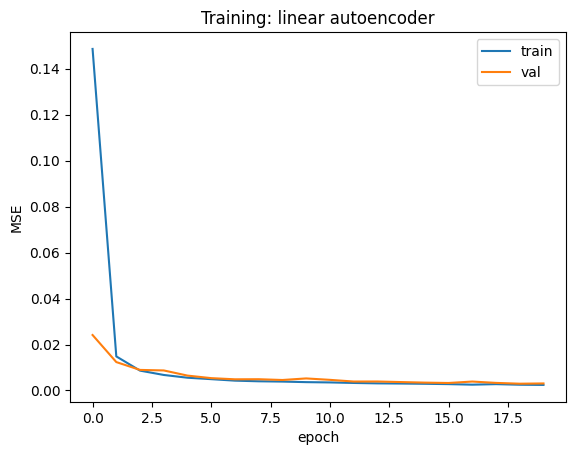

In [44]:
def train_autoencoder(model, train_loader, val_loader, epochs=20, noise=0.0, lr=1e-3, verbose=True):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    train_losses, val_losses = [], []

    for epoch in range(epochs):
        # --- train ---
        model.train()
        running, n = 0.0, 0
        for (xb,) in train_loader:
            xb = xb.to(device)
            x_in = xb + noise * torch.randn_like(xb)   # "break it" (if noise > 0)
            rebuilt = model(x_in)                      # 1. forward
            loss = loss_fn(rebuilt, xb)                # 2. loss vs the CLEAN original
            optimizer.zero_grad()
            loss.backward()                            # 3. backprop
            optimizer.step()                           # 4. update the weights
            running += loss.item() * len(xb); n += len(xb)
        train_losses.append(running / n)

        # --- validation (no learning) ---
        model.eval()
        running, n = 0.0, 0
        with torch.no_grad():
            for (xb,) in val_loader:
                xb = xb.to(device)
                running += loss_fn(model(xb), xb).item() * len(xb); n += len(xb)
        val_losses.append(running / n)

        if verbose:
            print(f"epoch {epoch+1:2d}: train loss {train_losses[-1]:.4f} | val loss {val_losses[-1]:.4f}")
    return train_losses, val_losses

train_losses, val_losses = train_autoencoder(model, train_loader, val_loader, epochs=20)

plt.plot(train_losses, label="train")
plt.plot(val_losses, label="val")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.title("Training: linear autoencoder")
plt.show()

## Step 8: Rebuild error for every test beat

In [45]:
def get_errors(model, X_data, batch_size=2048):
    model.eval()
    errs, rebuilt_all = [], []
    with torch.no_grad():
        for i in range(0, len(X_data), batch_size):
            x = torch.tensor(X_data[i : i + batch_size]).to(device)
            rebuilt = model(x)
            errs.append(((rebuilt - x) ** 2).mean(dim=1).cpu().numpy())   # MSE for EACH beat
            rebuilt_all.append(rebuilt.cpu().numpy())
    return np.concatenate(errs), np.concatenate(rebuilt_all)

val_err, _ = get_errors(model, X_val)
test_err, test_rebuilt = get_errors(model, X_test)

print("val (normal) mean error: ", val_err.mean().round(4))
print("test NORMAL mean error:  ", test_err[y_test == 0].mean().round(4))
print("test ANOMALY mean error: ", test_err[y_test == 1].mean().round(4))

df_err = pd.DataFrame({"type": labels_test, "error": test_err})
print(df_err.groupby("type")["error"].agg(["mean", "count"]).sort_values("mean").round(4))

val (normal) mean error:  0.0031
test NORMAL mean error:   0.0062
test ANOMALY mean error:  0.0579
        mean  count
type               
e     0.0010     16
S     0.0023      2
a     0.0049     23
N     0.0062  22119
A     0.0170    188
L     0.0171   3947
E     0.0197    106
R     0.0219   1337
F     0.0290    399
V     0.1269   3396


The model copies normal beats well and weird beats badly. That’s exactly what we wanted.
In anomaly detection: big error on weird beats = the alarm works, “something is wrong here!”

0.0031 , normal beats of people it KNOWS ( good copy)

0.0062 , normal beats of NEW people (good copy)

0.0579 → weird beats of new people(bad copy)

normal beat → SMALL error → good ✅ (no false alarm)
weird beat  → BIG error   → good ✅ (it raises the alarm)

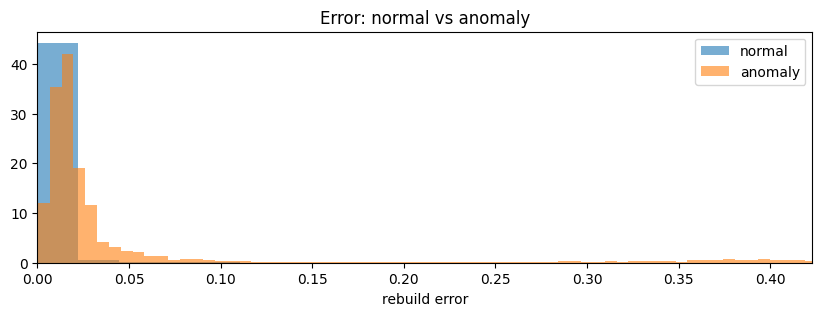

In [47]:
# 1. histogram: normal vs anomaly errors
plt.figure(figsize=(10, 3))
plt.hist(test_err[y_test == 0], bins=100, alpha=0.6, label="normal", density=True)
plt.hist(test_err[y_test == 1], bins=100, alpha=0.6, label="anomaly", density=True)
plt.xlim(0, np.percentile(test_err, 99))
plt.xlabel("rebuild error"); plt.legend(); plt.title("Error: normal vs anomaly")
plt.show()



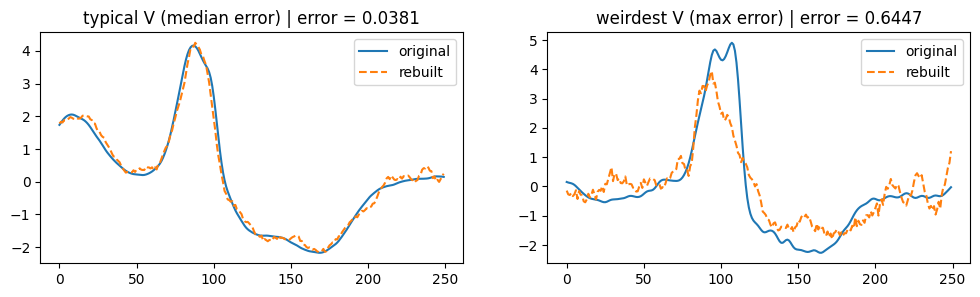

In [48]:
#v= most common weird beat in the test set (3,396 beats)
v_idx = np.where(labels_test == "V")[0]
v_err = test_err[v_idx]

pick = {"typical V (median error)": v_idx[np.argsort(v_err)[len(v_err) // 2]],
        "weirdest V (max error)":   v_idx[np.argmax(v_err)]}
#argsort - all the PVC positions, from smallest error to biggest
#[len // 2] → take the one in the middle = a typical PVC
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
for i, (title, k) in enumerate(pick.items()):
    ax[i].plot(X_test[k], label="original")
    ax[i].plot(test_rebuilt[k], label="rebuilt", linestyle="--")
    ax[i].set_title(f"{title} | error = {test_err[k]:.4f}")
    ax[i].legend()
plt.show()

Histogram:
Normal = all squeezed on the left (small errors)
Anomaly = spread out to the right, some up to 0.40
But a big part of the orange overlaps the blue on the left, those weird beats look normal to the model → they’ll be missed

We plot 250 numbers and connect the dots
The plot = the numbers, shown as a line
We plot PVC
1.I show the model a heartbeat

2.The model has to draw it again from memory

3.We compare: is the drawing like the original?

normal beat → should get a SMALL error (~0.006)
PVC         → should get a BIG error

2 PVCs · both got a big error · the model works ✅

## Step 9: Threshold + scores

In [50]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

def evaluate(name, val_score, test_score, p=95, show_cm=True):
    """threshold = p-th percentile of the VALIDATION normal scores (no peeking at test)"""
    threshold = np.percentile(val_score, p)
    y_pred = (test_score > threshold).astype(int)
    res = {"model": name,
           "AUC": roc_auc_score(y_test, test_score),
           "precision": precision_score(y_test, y_pred),
           "recall": recall_score(y_test, y_pred),
           "F1": f1_score(y_test, y_pred)}
    print(f"{name}: AUC {res['AUC']:.3f} | precision {res['precision']:.2f} | "
          f"recall {res['recall']:.2f} | F1 {res['F1']:.2f}")
    if show_cm:
        print("  confusion matrix:\n", confusion_matrix(y_test, y_pred))
    return res, y_pred

for p in [95, 99, 99.9]:
    print(f"--- threshold = {p}th percentile of val")
    evaluate(f"Linear AE ({p})", val_err, test_err, p=p)
    print()

--- threshold = 95th percentile of val
Linear AE (95): AUC 0.946 | precision 0.78 | recall 0.92 | F1 0.84
  confusion matrix:
 [[19635  2484]
 [  772  8642]]

--- threshold = 99th percentile of val
Linear AE (99): AUC 0.946 | precision 0.85 | recall 0.28 | F1 0.42
  confusion matrix:
 [[21646   473]
 [ 6794  2620]]

--- threshold = 99.9th percentile of val
Linear AE (99.9): AUC 0.946 | precision 0.89 | recall 0.11 | F1 0.19
  confusion matrix:
 [[22000   119]
 [ 8419   995]]



## Step 10: Which beat types are caught? (95th threshold)
For **N** the number = the **false alarm rate**. For the others = the **recall** of that type.

In [51]:
results = []            # we collect every model's scores here for the final comparison
caught_table = pd.DataFrame({"type": labels_test})

res, y_pred = evaluate("1. Linear AE", val_err, test_err, show_cm=False)
results.append(res)
caught_table["1. Linear AE"] = y_pred

print(caught_table.groupby("type")["1. Linear AE"].agg(["mean", "count"]).round(2).sort_values("mean"))

1. Linear AE: AUC 0.946 | precision 0.78 | recall 0.92 | F1 0.84
      mean  count
type             
S     0.00      2
e     0.00     16
a     0.09     23
N     0.11  22119
A     0.60    188
F     0.69    399
V     0.87   3396
E     0.90    106
R     0.94   1337
L     1.00   3947


# PART B: Improvements

## Step 11: Look inside the latent space (z)
*(from: MNIST_UMAP_vs_PCA, Swiss_Roll_PCA_tSNE_Isomap, Clustering_on_CNN_Features)*

Each beat → encoder → **z (32 numbers)** → UMAP → **2 numbers** → one dot.
- Do PVCs form their **own island**? (easy to catch)
- Are PACs **mixed** with normal beats? (hard to catch)

⚠️ In UMAP, distances between far islands don't mean much: look at **mixed vs separate**.

In [52]:
def get_z(model, X_data, batch_size=2048):
    model.eval()
    zs = []
    with torch.no_grad():
        for i in range(0, len(X_data), batch_size):
            zs.append(model.encoder(torch.tensor(X_data[i : i + batch_size]).to(device)).cpu().numpy())
    return np.concatenate(zs)

z_test = get_z(model, X_test)
print("z shape:", z_test.shape)

z shape: (31533, 32)


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


2D shape: (5000, 2)


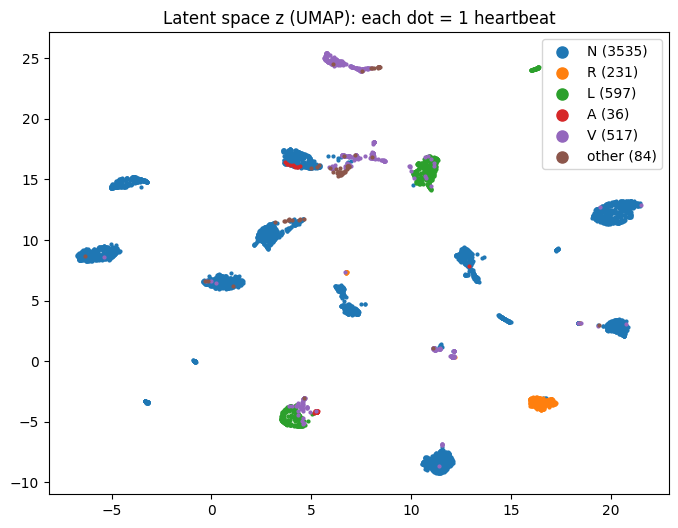

In [53]:
import umap

# 5,000 random test beats (UMAP on all of them is slow)
rng = np.random.default_rng(0)
idx = rng.choice(len(z_test), min(5000, len(z_test)), replace=False)
z_small = z_test[idx]
types_small = labels_test[idx]

z_2d = umap.UMAP(n_components=2, random_state=0).fit_transform(z_small)
print("2D shape:", z_2d.shape)

groups = np.where(np.isin(types_small, ["N", "V", "R", "L", "A"]), types_small, "other")

plt.figure(figsize=(8, 6))
for g in ["N", "R", "L", "A", "V", "other"]:
    m = groups == g
    if m.sum() > 0:
        plt.scatter(z_2d[m, 0], z_2d[m, 1], s=4, label=f"{g} ({m.sum()})")
plt.legend(markerscale=4)
plt.title("Latent space z (UMAP): each dot = 1 heartbeat")
plt.show()

In [54]:
# K-Means on z: does it find beat types WITHOUT labels?
from sklearn.cluster import KMeans

km = KMeans(n_clusters=6, random_state=0, n_init=10).fit(z_small)
print("rows = cluster, columns = real beat type")
print(pd.crosstab(km.labels_, groups))

rows = cluster, columns = real beat type
col_0   A    L     N    R    V  other
row_0                                
0       1    2  1575   15   13     13
1       1    0   287    0    0      0
2       0    0   917  216   82      6
3       0  349     4    0  141     29
4      10   13   741    0  225     36
5      24  233    11    0   56      0


## Step 12: Conv1d denoising autoencoder
*(from: Break It Then Fix It: `Conv2d` for images → `Conv1d` for signals)*

Two upgrades:
1. **Conv1d** layers: small filters slide along the beat → better at wave **shapes**
2. **Denoising**: add noise to the input, the target is the clean beat → learns the **real** shape, less sensitive to small differences between people

Shapes: `250 → (16 × 125) → (32 × 25) → z = 32 → (32 × 25) → (16 × 125) → 250`

In [55]:
class ConvBeatAutoencoder(nn.Module):
    def __init__(self, z_dimension=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Unflatten(1, (1, 250)),                  # [B, 250] -> [B, 1, 250]
            nn.Conv1d(1, 16, kernel_size=7, padding=3),
            nn.ReLU(),
            nn.MaxPool1d(2),                            # [B, 16, 125]
            nn.Conv1d(16, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(5),                            # [B, 32, 25]
            nn.Flatten(),                               # [B, 800]
            nn.Linear(32 * 25, z_dimension)             # [B, z]
        )
        self.decoder = nn.Sequential(
            nn.Linear(z_dimension, 32 * 25),
            nn.ReLU(),
            nn.Unflatten(1, (32, 25)),                  # [B, 32, 25]
            nn.ConvTranspose1d(32, 16, kernel_size=5, stride=5),   # [B, 16, 125]
            nn.ReLU(),
            nn.ConvTranspose1d(16, 8, kernel_size=2, stride=2),    # [B, 8, 250]
            nn.ReLU(),
            nn.Conv1d(8, 1, kernel_size=7, padding=3),  # [B, 1, 250]
            nn.Flatten()                                # [B, 250]
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

torch.manual_seed(0)
conv_model = ConvBeatAutoencoder().to(device)
sample = torch.tensor(X_tr[:1]).to(device)
print("input:", sample.shape, "| z:", conv_model.encoder(sample).shape, "| output:", conv_model(sample).shape)

input: torch.Size([1, 250]) | z: torch.Size([1, 32]) | output: torch.Size([1, 250])


epoch  1: train loss 0.2636 | val loss 0.0375
epoch  2: train loss 0.0223 | val loss 0.0162
epoch  3: train loss 0.0124 | val loss 0.0115
epoch  4: train loss 0.0095 | val loss 0.0090
epoch  5: train loss 0.0079 | val loss 0.0079
epoch  6: train loss 0.0070 | val loss 0.0073
epoch  7: train loss 0.0063 | val loss 0.0067
epoch  8: train loss 0.0058 | val loss 0.0060
epoch  9: train loss 0.0055 | val loss 0.0059
epoch 10: train loss 0.0052 | val loss 0.0054
epoch 11: train loss 0.0049 | val loss 0.0051
epoch 12: train loss 0.0047 | val loss 0.0048
epoch 13: train loss 0.0045 | val loss 0.0046
epoch 14: train loss 0.0044 | val loss 0.0047
epoch 15: train loss 0.0043 | val loss 0.0048
epoch 16: train loss 0.0041 | val loss 0.0042
epoch 17: train loss 0.0041 | val loss 0.0049
epoch 18: train loss 0.0039 | val loss 0.0040
epoch 19: train loss 0.0039 | val loss 0.0040
epoch 20: train loss 0.0038 | val loss 0.0038


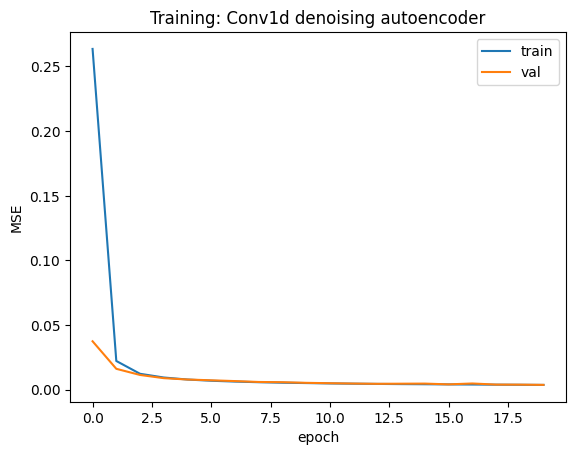

In [56]:
NOISE = 0.1     # how strong the "break it" noise is (in scaled units)
conv_train_losses, conv_val_losses = train_autoencoder(conv_model, train_loader, val_loader,
                                                       epochs=20, noise=NOISE)

plt.plot(conv_train_losses, label="train")
plt.plot(conv_val_losses, label="val")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.title("Training: Conv1d denoising autoencoder")
plt.show()

In [ ]:
conv_val_err, _ = get_errors(conv_model, X_val)
conv_test_err, conv_test_rebuilt = get_errors(conv_model, X_test)

res, y_pred = evaluate("2. Conv denoising AE", conv_val_err, conv_test_err)
results.append(res)
caught_table["2. Conv denoising AE"] = y_pred

## Step 13: KNN distance in latent space
*(from: KNN lessons, Qdrant vector search)*

Idea: store the **z of all normal training beats**. For a new beat, find its **5 nearest normal neighbors**.
- Close to normal beats → normal ✅
- Far from all of them → 🚨

This is a **second detector**, different from the rebuild error. (Qdrant does the same search, faster, for millions of vectors.)

In [57]:
from sklearn.neighbors import NearestNeighbors

z_tr   = get_z(conv_model, X_tr)
z_val  = get_z(conv_model, X_val)
z_testc = get_z(conv_model, X_test)

knn = NearestNeighbors(n_neighbors=5).fit(z_tr)

def knn_score(z):
    dist, _ = knn.kneighbors(z)
    return dist.mean(axis=1)          # average distance to the 5 nearest NORMAL beats

knn_val  = knn_score(z_val)
knn_test = knn_score(z_testc)

res, y_pred = evaluate("3. KNN distance (z)", knn_val, knn_test)
results.append(res)
caught_table["3. KNN distance (z)"] = y_pred

3. KNN distance (z): AUC 0.887 | precision 0.37 | recall 0.99 | F1 0.54
  confusion matrix:
 [[ 6131 15988]
 [  109  9305]]


## Step 14: RR timing score
*(from: Feature engineering)*

The autoencoders only see **shape**. PACs and junctional beats look normal but come at the **wrong time**.

`rr_score` = how far the timing is from this patient's usual rhythm:
- normal beat: `rr_prev ≈ rr_mean` and `rr_next ≈ rr_mean` → score ≈ 0
- PAC: early (`rr_prev` short) + a pause after (`rr_next` long) → high score

In [58]:
def rr_score(rows):
    prev_ratio = all_rr_prev[rows] / all_rr_mean[rows]
    next_ratio = all_rr_next[rows] / all_rr_mean[rows]
    return np.abs(np.log(prev_ratio)) + np.abs(np.log(next_ratio))

rr_val  = rr_score(val_idx)
rr_test = rr_score(test_idx)

print("median rr_score by type:")
print(pd.DataFrame({"type": labels_test, "rr_score": rr_test}).groupby("type")["rr_score"].median().round(2).sort_values())

res, y_pred = evaluate("4. RR timing only", rr_val, rr_test)
results.append(res)
caught_table["4. RR timing only"] = y_pred

median rr_score by type:
type
L    0.07
R    0.09
N    0.10
E    0.16
S    0.22
F    0.26
e    0.31
V    0.59
a    0.66
A    1.16
Name: rr_score, dtype: float64
4. RR timing only: AUC 0.628 | precision 0.60 | recall 0.13 | F1 0.21
  confusion matrix:
 [[21334   785]
 [ 8234  1180]]


## Step 15: Ensemble: combine shape + neighbors + timing
*(from: Ensembling)*

Each score has different units, so first turn each one into **"how unusual compared to normal validation beats"** (a z-score using the val mean & std: no peeking at test!). Then:

**final score = the highest of the 3** → a beat is flagged if its **shape OR its neighbors OR its timing** is unusual.

In [59]:
def standardize(val_s, test_s):
    v, t = np.log1p(val_s), np.log1p(test_s)       # log: errors are skewed
    m, s = v.mean(), v.std()                       # learned from VALIDATION normals only
    return (v - m) / s, (t - m) / s

ae_v, ae_t   = standardize(conv_val_err, conv_test_err)
knn_v, knn_t = standardize(knn_val, knn_test)
rr_v, rr_t   = standardize(rr_val, rr_test)

ens_val  = np.max([ae_v, knn_v, rr_v], axis=0)
ens_test = np.max([ae_t, knn_t, rr_t], axis=0)

res, y_pred = evaluate("5. Ensemble (max)", ens_val, ens_test)
results.append(res)
caught_table["5. Ensemble (max)"] = y_pred

NameError: name 'conv_val_err' is not defined

## Step 16: Final comparison
*(from: Classification threshold intuition)*

The PR curve shows **every** possible threshold: up and to the right = better.

In [ ]:
comparison = pd.DataFrame(results).set_index("model").round(3)
print(comparison)

In [ ]:
# recall per beat type, for every model (for N = false alarm rate)
per_type = caught_table.groupby("type").mean().round(2)
per_type["count"] = caught_table["type"].value_counts()
print(per_type.sort_values("count", ascending=False))

In [ ]:
from sklearn.metrics import precision_recall_curve

scores = {"1. Linear AE": test_err, "2. Conv denoising AE": conv_test_err,
          "3. KNN distance (z)": knn_test, "4. RR timing only": rr_test, "5. Ensemble (max)": ens_test}

plt.figure(figsize=(7, 5))
for name, s in scores.items():
    prec, rec, _ = precision_recall_curve(y_test, s)
    plt.plot(rec, prec, label=name)
plt.xlabel("recall"); plt.ylabel("precision"); plt.legend(); plt.title("Precision-Recall curves (test)")
plt.grid(alpha=0.3)
plt.show()

## Step 17: K-Fold by patient: mean ± std
*(from: K-Fold notebooks)*

One random split can be lucky or unlucky. **GroupKFold** splits the **patients** into 5 groups and takes turns: every patient is in the test set exactly once.

⏳ Trains 5 conv models: about 5–10 min on GPU, longer on CPU (turn on the GPU: Runtime → Change runtime type).

In [ ]:
from sklearn.model_selection import GroupKFold

CV_EPOCHS = 10
cv_rows = []

for fold, (tr_rows, te_rows) in enumerate(GroupKFold(n_splits=5).split(all_beats, y, groups=patient)):
    # scale with THIS fold's train normal beats
    Xf = all_beats.astype(np.float32)
    nrm = tr_rows[y[tr_rows] == 0]
    m, s = Xf[nrm].mean(), Xf[nrm].std()
    Xf = (Xf - m) / s

    rng = np.random.default_rng(fold)
    perm = rng.permutation(nrm)
    n_v = int(0.1 * len(perm))
    v_rows, t_rows = perm[:n_v], perm[n_v:]

    tl = DataLoader(TensorDataset(torch.tensor(Xf[t_rows])), batch_size=256, shuffle=True)
    vl = DataLoader(TensorDataset(torch.tensor(Xf[v_rows])), batch_size=256)

    torch.manual_seed(fold)
    cm_model = ConvBeatAutoencoder().to(device)
    train_autoencoder(cm_model, tl, vl, epochs=CV_EPOCHS, noise=NOISE, verbose=False)

    # scores: AE error + KNN + RR -> ensemble
    ae_vf, _ = get_errors(cm_model, Xf[v_rows]); ae_tf, _ = get_errors(cm_model, Xf[te_rows])
    knn_f = NearestNeighbors(n_neighbors=5).fit(get_z(cm_model, Xf[t_rows]))
    kn_vf = knn_f.kneighbors(get_z(cm_model, Xf[v_rows]))[0].mean(axis=1)
    kn_tf = knn_f.kneighbors(get_z(cm_model, Xf[te_rows]))[0].mean(axis=1)
    rr_vf, rr_tf = rr_score(v_rows), rr_score(te_rows)

    parts_v, parts_t = [], []
    for a, b in [(ae_vf, ae_tf), (kn_vf, kn_tf), (rr_vf, rr_tf)]:
        sv, st = standardize(a, b); parts_v.append(sv); parts_t.append(st)
    ens_vf, ens_tf = np.max(parts_v, axis=0), np.max(parts_t, axis=0)

    yt = y[te_rows]
    for name, sv, st in [("Conv AE", ae_vf, ae_tf), ("Ensemble", ens_vf, ens_tf)]:
        thr = np.percentile(sv, 95)
        yp = (st > thr).astype(int)
        cv_rows.append({"fold": fold + 1, "model": name, "AUC": roc_auc_score(yt, st),
                        "recall": recall_score(yt, yp), "precision": precision_score(yt, yp),
                        "F1": f1_score(yt, yp)})
    print(f"fold {fold+1} done: test patients = {len(np.unique(patient[te_rows]))}")

cv = pd.DataFrame(cv_rows)
print(cv.round(3))
print()
print("mean ± std over 5 folds:")
summary = cv.groupby("model")[["AUC", "recall", "precision", "F1"]].agg(["mean", "std"]).round(3)
print(summary)

## Results summary (fill in after running)
| Model | AUC | Recall | Precision | F1 |
|---|---|---|---|---|
| 1. Linear AE (V1) | 0.87 | 0.80 | 0.56 | 0.66 |
| 2. Conv denoising AE | | | | |
| 3. KNN distance | | | | |
| 4. RR timing | | | | |
| 5. Ensemble | | | | |
| **5-fold CV (Ensemble)** | ± | ± | ± | ± |